# Task 1 — Sales Data Analysis

## Inter Alpha Internship

### Objective

Analyze sales data to identify sales trends, seasonal patterns,
product performance, regional performance, and key business insights.

### Tools Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Excel

### Dataset

Sample Superstore Dataset

In [160]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [161]:
file_path = "../data/Sample - Superstore.csv"

df = pd.read_csv(
    file_path,
    encoding="latin1"
)

print("Dataset loaded successfully.")

Dataset loaded successfully.


## 1. Dataset Overview

Before performing any analysis, we first inspect the structure,
dimensions, columns, data types, missing values, and duplicate records.

In [162]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape:
(9994, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [163]:
df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [164]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [165]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [166]:
print("Duplicate Rows:")
print(df.duplicated().sum())

Duplicate Rows:
0


## 2. Data Quality Assessment

Before performing exploratory data analysis, the dataset was checked for:

- Missing values
- Duplicate records
- Incorrect data types
- Date formatting
- Numerical column consistency

The dataset contains 9,994 records and 21 columns. No missing values were identified.

In [167]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [168]:
df.dtypes

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

### Date Conversion

The `Order Date` and `Ship Date` columns are converted from text/object
format into Pandas datetime format to enable time-series and seasonal analysis.

In [169]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [170]:
df[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

In [171]:
numeric_columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit"
]

df[numeric_columns].dtypes

Sales       float64
Quantity      int64
Discount    float64
Profit      float64
dtype: object

In [172]:
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Sales,9994.0,229.858001,623.245101,0.444,17.28000,54.4900,209.940,22638.480
Quantity,9994.0,3.789574,2.225110,1.000,2.00000,3.0000,5.000,14.000
Discount,9994.0,0.156203,0.206452,0.000,0.00000,0.2000,0.200,0.800
Profit,9994.0,28.656896,234.260108,-6599.978,1.72875,8.6665,29.364,8399.976


In [173]:
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())

Quantity <= 0: 0


In [174]:
print("Sales <= 0:", (df["Sales"] <= 0).sum())

Sales <= 0: 0


In [175]:
print("Discount > 1:", (df["Discount"] > 1).sum())

Discount > 1: 0


In [176]:
print("Minimum Order Date:", df["Order Date"].min())
print("Maximum Order Date:", df["Order Date"].max())

Minimum Order Date: 2014-01-03 00:00:00
Maximum Order Date: 2017-12-30 00:00:00


## 3. Feature Engineering

Additional time-based features are created from the order date to support
yearly, monthly, quarterly, and seasonal sales analysis.

In [177]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()
df["Quarter"] = df["Order Date"].dt.quarter

In [178]:
df[
    [
        "Order Date",
        "Year",
        "Month",
        "Month Name",
        "Quarter"
    ]
].head()

,Order Date,Year,Month,Month Name,Quarter
0,2016-11-08,2016,11,November,4
1,2016-11-08,2016,11,November,4
2,2016-06-12,2016,6,June,2
3,2015-10-11,2015,10,October,4
4,2015-10-11,2015,10,October,4


In [179]:
df["Year-Month"] = df["Order Date"].dt.to_period("M")

In [180]:
df[
    [
        "Order Date",
        "Year",
        "Month",
        "Month Name",
        "Quarter",
        "Year-Month"
    ]
].head()

,Order Date,Year,Month,Month Name,Quarter,Year-Month
0,2016-11-08,2016,11,November,4,2016-11
1,2016-11-08,2016,11,November,4,2016-11
2,2016-06-12,2016,6,June,2,2016-06
3,2015-10-11,2015,10,October,4,2015-10
4,2015-10-11,2015,10,October,4,2015-10


In [181]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Final Dataset Shape: (9994, 26)

Missing Values:
0

Duplicate Rows:
0


## 4. Exploratory Data Analysis

This section explores the overall sales performance, order volume,
customer base, product portfolio, and profitability of the business.

The analysis focuses on key performance indicators (KPIs) that provide
a high-level understanding of the sales dataset before investigating
trends, seasonality, products, and regional performance.

In [182]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_products = df["Product ID"].nunique()

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Total Orders: {total_orders:,}")
print(f"Unique Customers: {total_customers:,}")
print(f"Unique Products: {total_products:,}")

Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Quantity Sold: 37,873
Total Orders: 5,009
Unique Customers: 793
Unique Products: 1,862


In [183]:
profit_margin = (total_profit / total_sales) * 100

print(f"Overall Profit Margin: {profit_margin:.2f}%")

Overall Profit Margin: 12.47%


In [184]:
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Total Profit",
        "Total Quantity Sold",
        "Total Orders",
        "Unique Customers",
        "Unique Products",
        "Profit Margin"
    ],
    "Value": [
        total_sales,
        total_profit,
        total_quantity,
        total_orders,
        total_customers,
        total_products,
        profit_margin
    ]
})

kpi_summary

,KPI,Value
0,Total Sales,2.297201e+06
1,Total Profit,2.863970e+05
2,Total Quantity Sold,3.787300e+04
3,Total Orders,5.009000e+03
4,Unique Customers,7.930000e+02
5,Unique Products,1.862000e+03
6,Profit Margin,1.246722e+01


### Sales and Profit Distribution

The distributions of sales and profit are examined to understand
the spread of transaction values and identify unusually high or
low-performing transactions.

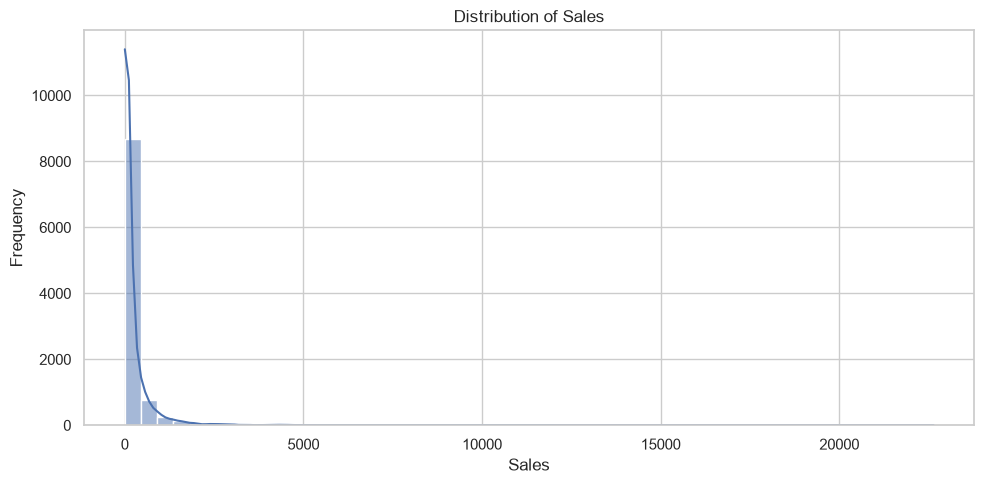

In [185]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Sales",
    bins=50,
    kde=True
)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

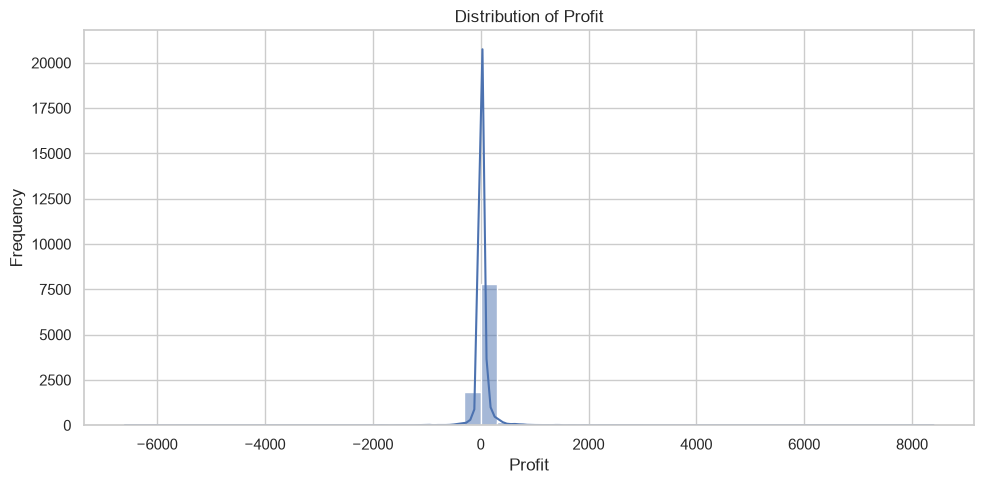

In [186]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Profit",
    bins=50,
    kde=True
)

plt.title("Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

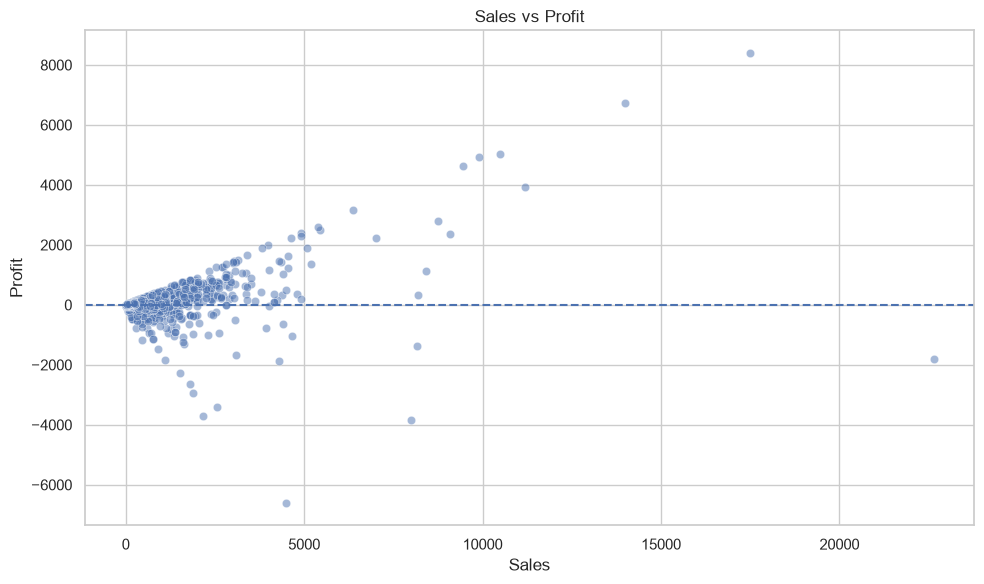

In [187]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Profit",
    alpha=0.5
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")

plt.tight_layout()

plt.savefig(
    "../outputs/sales_vs_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Customer Segment Analysis

Sales and profitability are compared across customer segments to
identify which customer groups contribute most to business performance.

In [188]:
segment_performance = (
    df.groupby("Segment")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"),
        Orders=("Order ID", "nunique"),
        Customers=("Customer ID", "nunique")
    )
    .sort_values("Sales", ascending=False)
)

segment_performance

,Sales,Profit,Quantity,Orders,Customers
Segment,,,,,
Consumer,1.161401e+06,134119.2092,19521,2586,409
Corporate,7.061464e+05,91979.1340,11608,1514,236
Home Office,4.296531e+05,60298.6785,6744,909,148


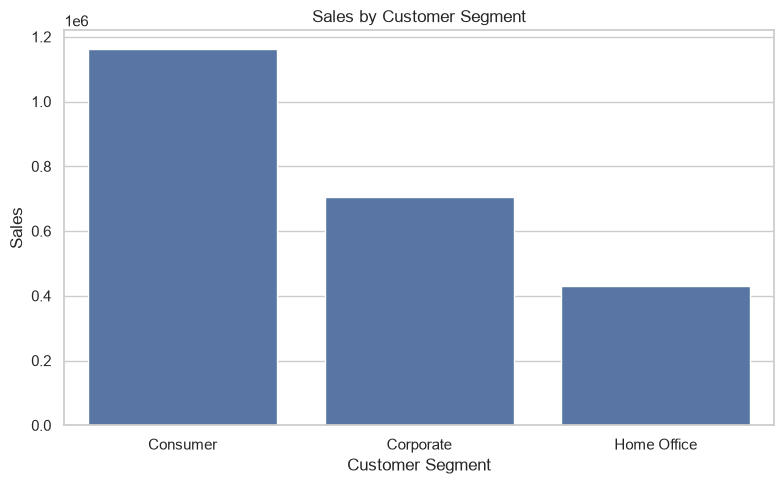

In [189]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=segment_performance.reset_index(),
    x="Segment",
    y="Sales"
)

plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Sales")

plt.tight_layout()
plt.show()

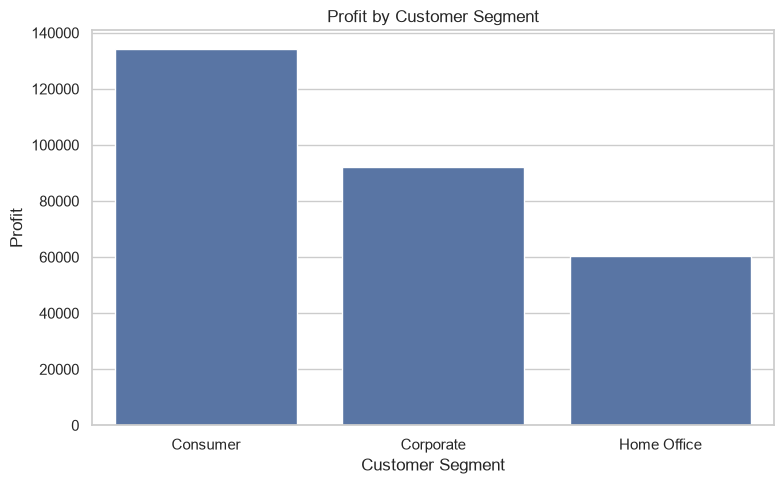

In [190]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=segment_performance.reset_index(),
    x="Segment",
    y="Profit"
)

plt.title("Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Profit")

plt.tight_layout()
plt.show()

### Category Performance

Sales and profit are analyzed across product categories to determine
which categories contribute most strongly to overall business performance.

In [191]:
category_performance = (
    df.groupby("Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"),
        Orders=("Order ID", "nunique")
    )
    .sort_values("Sales", ascending=False)
)

category_performance

,Sales,Profit,Quantity,Orders
Category,,,,
Technology,836154.0330,145454.9481,6939,1544
Furniture,741999.7953,18451.2728,8028,1764
Office Supplies,719047.0320,122490.8008,22906,3742


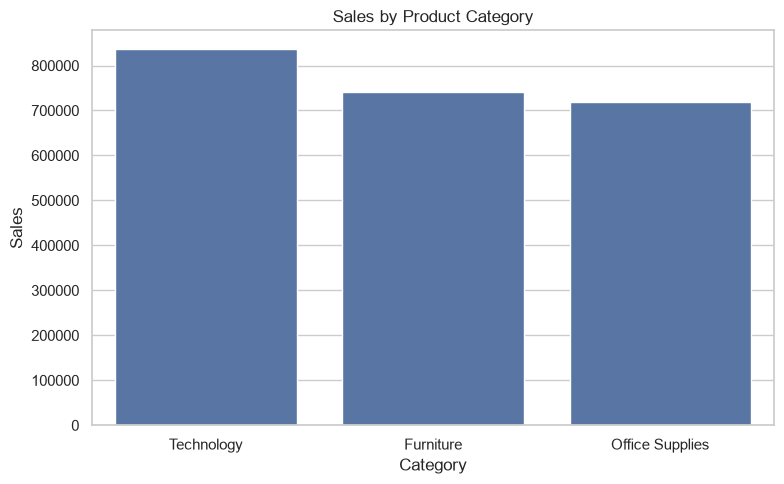

In [192]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=category_performance.reset_index(),
    x="Category",
    y="Sales"
)

plt.title("Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Sales")

plt.tight_layout()
plt.show()

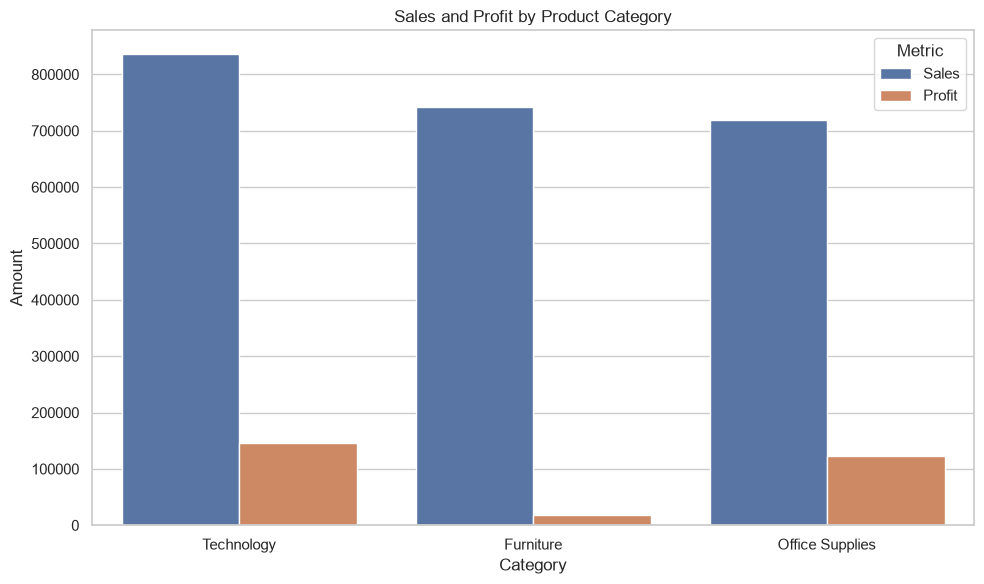

In [193]:
category_plot_data = (
    category_performance
    .reset_index()
    .melt(
        id_vars="Category",
        value_vars=["Sales", "Profit"],
        var_name="Metric",
        value_name="Value"
    )
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_plot_data,
    x="Category",
    y="Value",
    hue="Metric"
)

plt.title("Sales and Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Amount")

plt.tight_layout()

plt.savefig(
    "../outputs/category_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

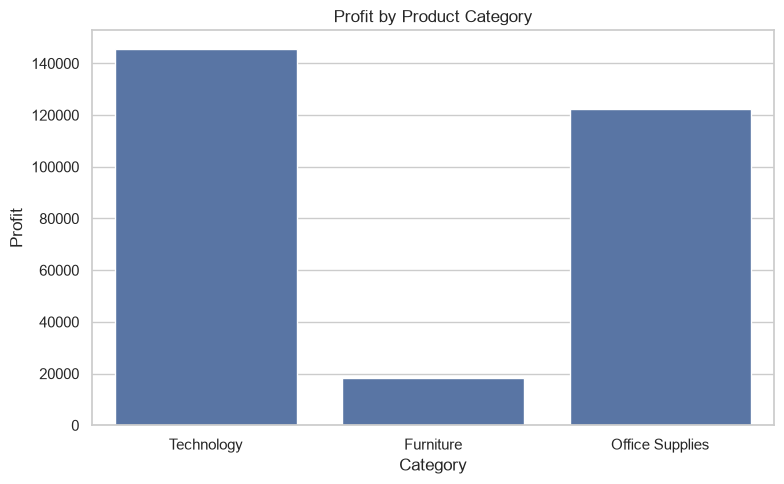

In [194]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=category_performance.reset_index(),
    x="Category",
    y="Profit"
)

plt.title("Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Profit")

plt.tight_layout()
plt.show()

In [195]:
subcategory_performance = (
    df.groupby("Sub-Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
    .sort_values("Sales", ascending=False)
)

subcategory_performance

,Sales,Profit,Quantity
Sub-Category,,,
Phones,330007.0540,44515.7306,3289
Chairs,328449.1030,26590.1663,2356
Storage,223843.6080,21278.8264,3158
Tables,206965.5320,-17725.4811,1241
Binders,203412.7330,30221.7633,5974
Machines,189238.6310,3384.7569,440
Accessories,167380.3180,41936.6357,2976
Copiers,149528.0300,55617.8249,234
Bookcases,114879.9963,-3472.5560,868


In [196]:
subcategory_performance.head(10)

,Sales,Profit,Quantity
Sub-Category,,,
Phones,330007.0540,44515.7306,3289
Chairs,328449.1030,26590.1663,2356
Storage,223843.6080,21278.8264,3158
Tables,206965.5320,-17725.4811,1241
Binders,203412.7330,30221.7633,5974
Machines,189238.6310,3384.7569,440
Accessories,167380.3180,41936.6357,2976
Copiers,149528.0300,55617.8249,234
Bookcases,114879.9963,-3472.5560,868


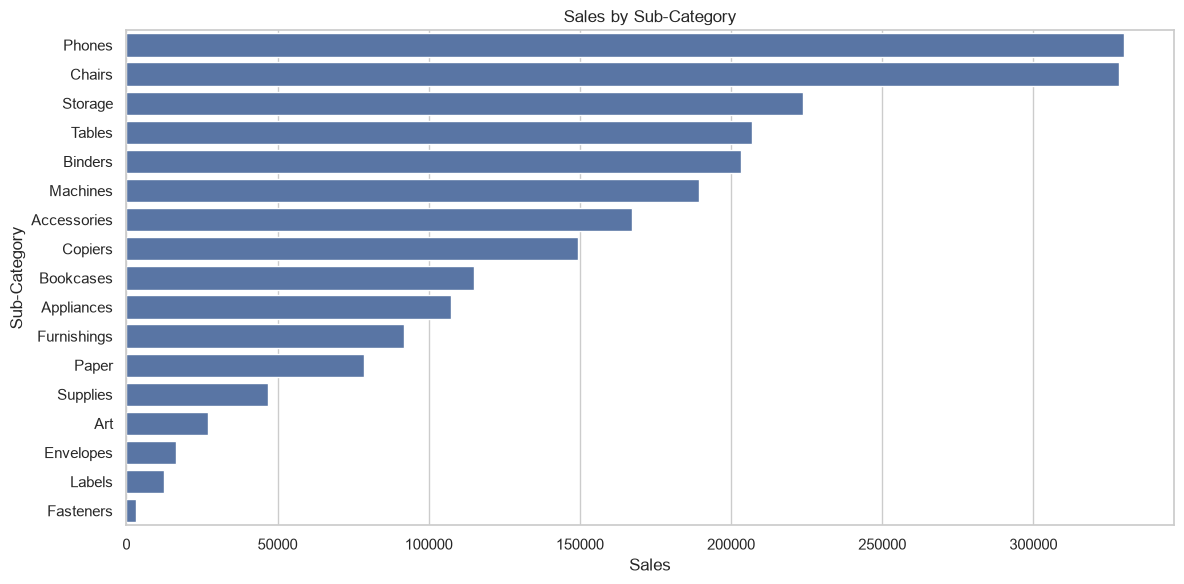

In [197]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=subcategory_performance.reset_index(),
    x="Sales",
    y="Sub-Category"
)

plt.title("Sales by Sub-Category")
plt.xlabel("Sales")
plt.ylabel("Sub-Category")

plt.tight_layout()
plt.show()

In [198]:
region_performance = (
    df.groupby("Region")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"),
        Orders=("Order ID", "nunique")
    )
    .sort_values("Sales", ascending=False)
)

region_performance

,Sales,Profit,Quantity,Orders
Region,,,,
West,725457.8245,108418.4489,12266,1611
East,678781.2400,91522.7800,10618,1401
Central,501239.8908,39706.3625,8780,1175
South,391721.9050,46749.4303,6209,822


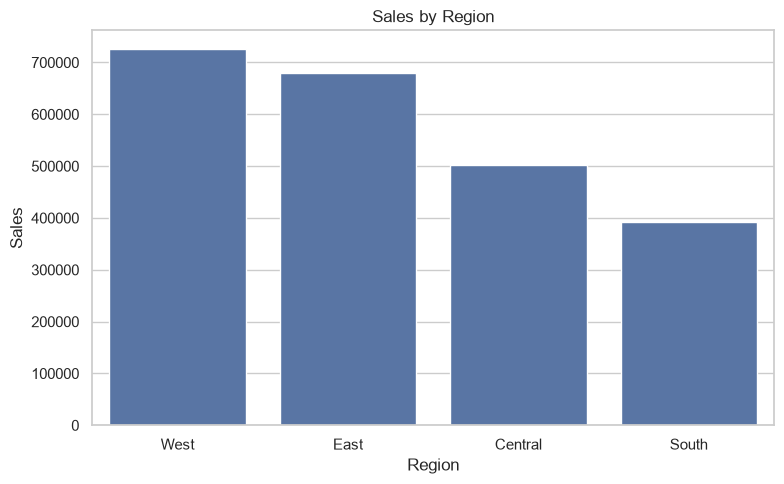

In [199]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=region_performance.reset_index(),
    x="Region",
    y="Sales"
)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")

plt.tight_layout()
plt.show()

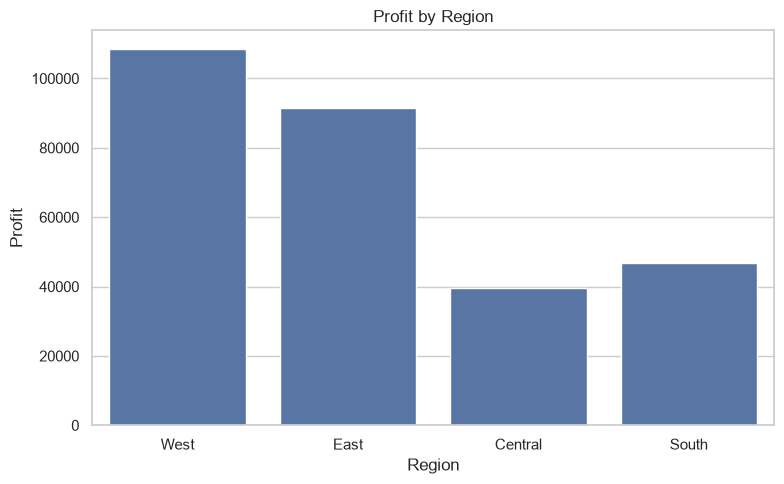

In [200]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=region_performance.reset_index(),
    x="Region",
    y="Profit"
)

plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Profit")

plt.tight_layout()
plt.show()

In [201]:
region_performance["Profit Margin (%)"] = (
    region_performance["Profit"]
    / region_performance["Sales"]
    * 100
)

region_performance

,Sales,Profit,Quantity,Orders,Profit Margin (%)
Region,,,,,
West,725457.8245,108418.4489,12266,1611,14.944831
East,678781.2400,91522.7800,10618,1401,13.483399
Central,501239.8908,39706.3625,8780,1175,7.921629
South,391721.9050,46749.4303,6209,822,11.934342


## 5. Sales Trend Analysis

Sales trends are analyzed over yearly and monthly periods to understand
the overall growth pattern and identify periods of stronger or weaker
sales performance.

In [202]:
yearly_performance = (
    df.groupby("Year")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"),
        Orders=("Order ID", "nunique")
    )
)

yearly_performance

,Sales,Profit,Quantity,Orders
Year,,,,
2014,484247.4981,49543.9741,7581,969
2015,470532.5090,61618.6037,7979,1038
2016,609205.5980,81795.1743,9837,1315
2017,733215.2552,93439.2696,12476,1687


In [203]:
yearly_performance["Sales Growth (%)"] = (
    yearly_performance["Sales"]
    .pct_change()
    * 100
)

yearly_performance

,Sales,Profit,Quantity,Orders,Sales Growth (%)
Year,,,,,
2014,484247.4981,49543.9741,7581,969,NaN
2015,470532.5090,61618.6037,7979,1038,-2.832227
2016,609205.5980,81795.1743,9837,1315,29.471521
2017,733215.2552,93439.2696,12476,1687,20.355962


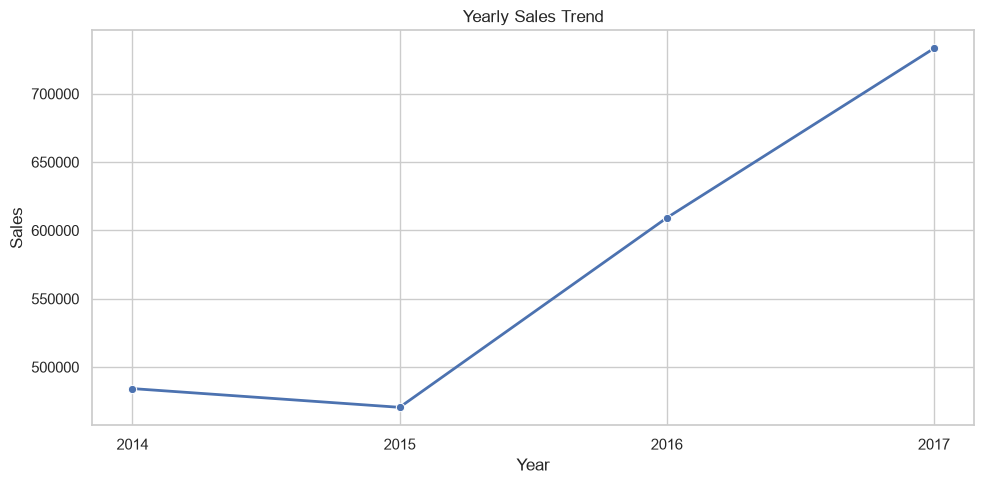

In [204]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_performance.reset_index(),
    x="Year",
    y="Sales",
    marker="o",
    linewidth=2
)

plt.title("Yearly Sales Trend")
plt.xlabel("Year")
plt.ylabel("Sales")

plt.xticks(yearly_performance.index)

plt.tight_layout()

plt.savefig(
    "../outputs/yearly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

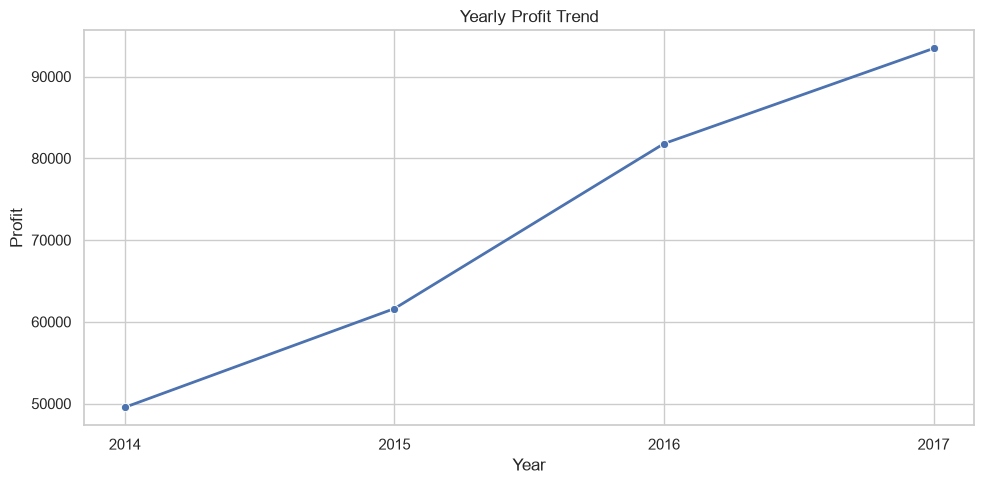

In [205]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_performance.reset_index(),
    x="Year",
    y="Profit",
    marker="o",
    linewidth=2
)

plt.title("Yearly Profit Trend")
plt.xlabel("Year")
plt.ylabel("Profit")

plt.xticks(yearly_performance.index)

plt.tight_layout()
plt.show()

In [206]:
monthly_sales = (
    df.groupby("Year-Month")["Sales"]
    .sum()
)

In [207]:
monthly_sales.head(10)

Year-Month
2014-01    14236.8950
2014-02     4519.8920
2014-03    55691.0090
2014-04    28295.3450
2014-05    23648.2870
2014-06    34595.1276
2014-07    33946.3930
2014-08    27909.4685
2014-09    81777.3508
2014-10    31453.3930
Freq: M, Name: Sales, dtype: float64

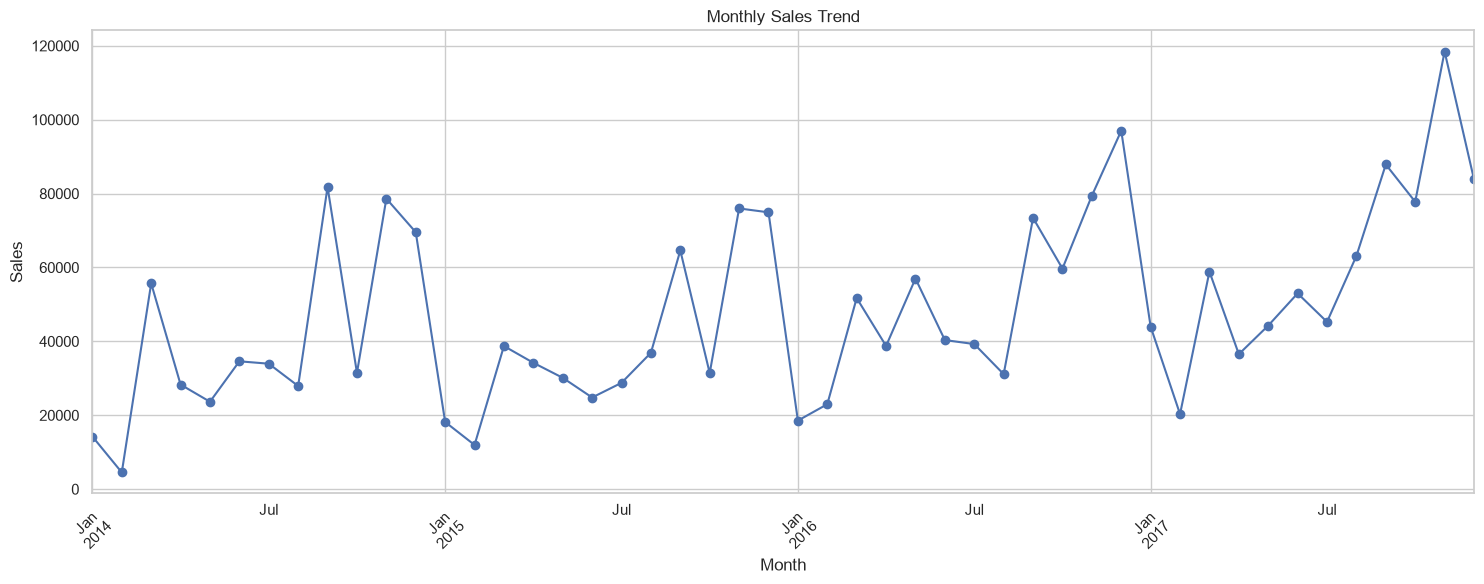

In [208]:
plt.figure(figsize=(15, 6))

monthly_sales.plot(
    marker="o",
    linewidth=1.5
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "../outputs/monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [209]:
monthly_profit = (
    df.groupby("Year-Month")["Profit"]
    .sum()
)

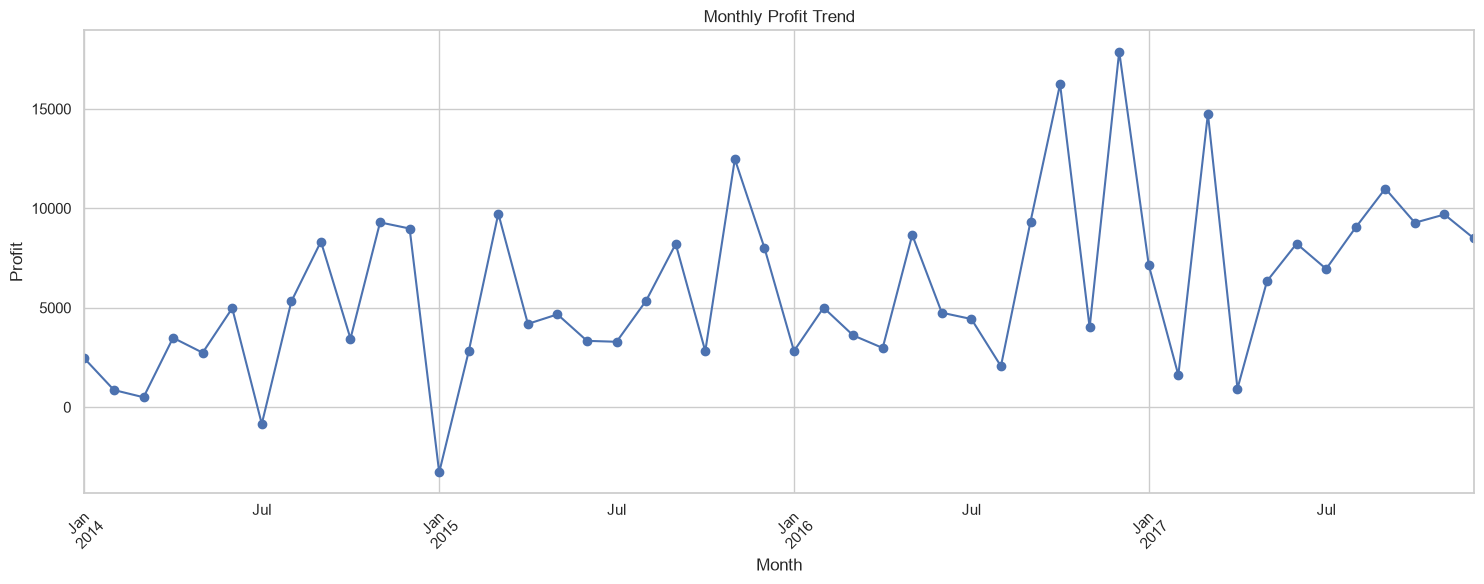

In [210]:
plt.figure(figsize=(15, 6))

monthly_profit.plot(
    marker="o",
    linewidth=1.5
)

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [211]:
monthly_profit = (
    df.groupby("Year-Month")["Profit"]
    .sum()
)

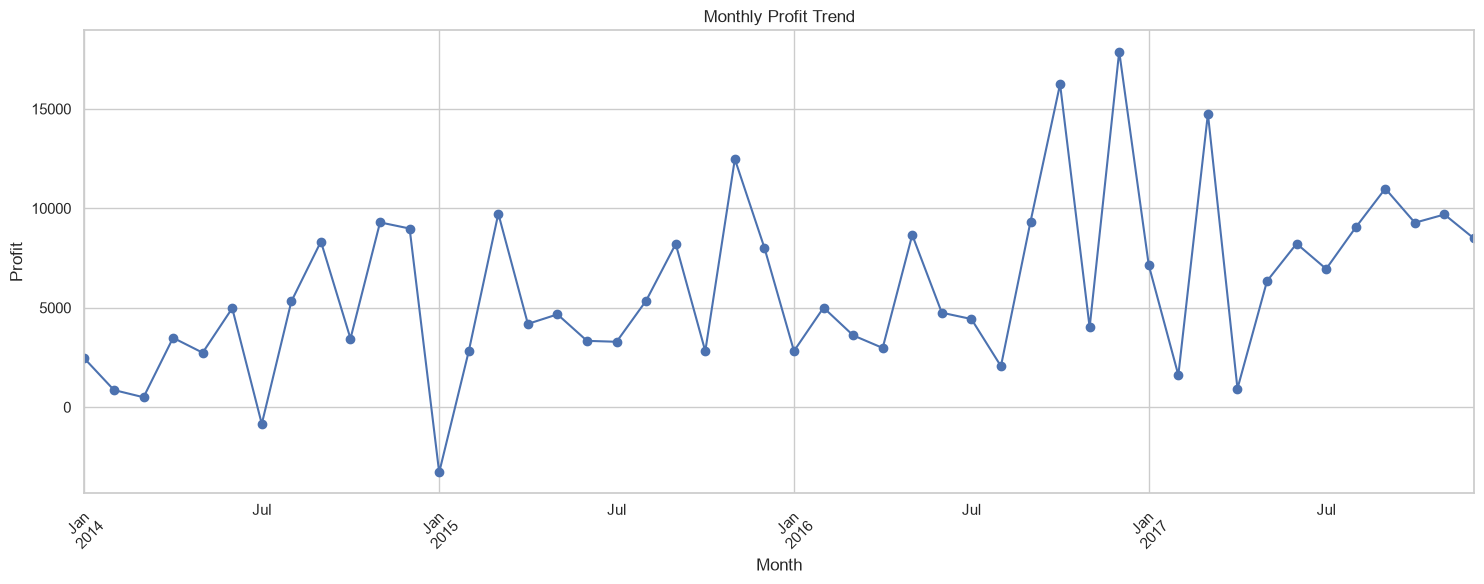

In [212]:
plt.figure(figsize=(15, 6))

monthly_profit.plot(
    marker="o",
    linewidth=1.5
)

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [213]:
seasonal_sales = (
    df.groupby("Month")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
)

seasonal_sales

,Sales,Profit
Month,,
1,94924.8356,9134.4461
2,59751.2514,10294.6107
3,205005.4888,28594.6872
4,137762.1286,11587.4363
5,155028.8117,22411.3078
6,152718.6793,21285.7954
7,147238.0970,13832.6648
8,159044.0630,21776.9384
9,307649.9457,36857.4753


In [214]:
seasonal_sales = seasonal_sales.sort_index()

seasonal_sales

,Sales,Profit
Month,,
1,94924.8356,9134.4461
2,59751.2514,10294.6107
3,205005.4888,28594.6872
4,137762.1286,11587.4363
5,155028.8117,22411.3078
6,152718.6793,21285.7954
7,147238.0970,13832.6648
8,159044.0630,21776.9384
9,307649.9457,36857.4753


In [215]:
monthly_seasonality = (
    df.groupby("Month")["Sales"]
    .mean()
)

monthly_seasonality

Month
1     249.146550
2     199.170838
3     294.548116
4     206.230731
5     210.923553
6     212.996763
7     207.377601
8     225.274877
9     222.451154
10    244.594609
11    239.606438
12    231.032318
Name: Sales, dtype: float64

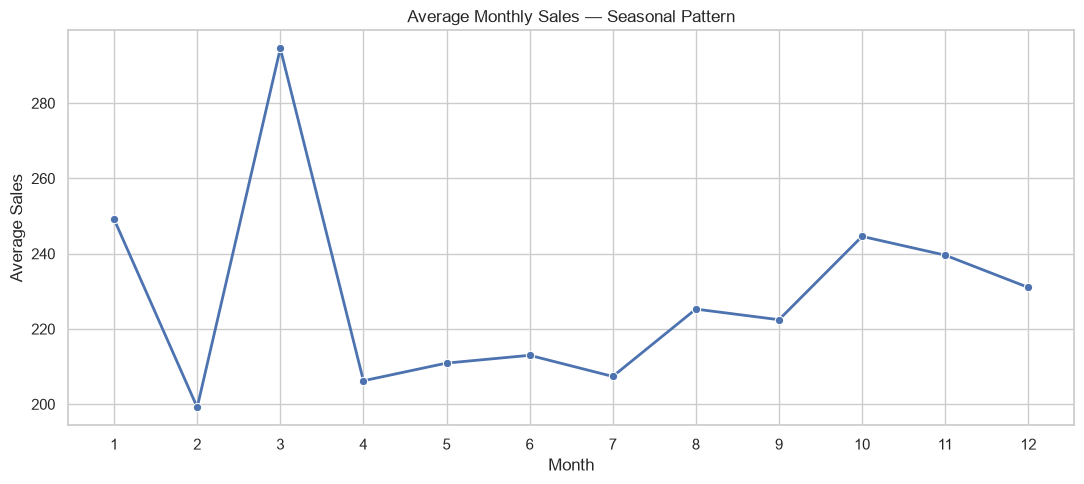

In [216]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    x=monthly_seasonality.index,
    y=monthly_seasonality.values,
    marker="o",
    linewidth=2
)

plt.title("Average Monthly Sales — Seasonal Pattern")
plt.xlabel("Month")
plt.ylabel("Average Sales")

plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

In [217]:
month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

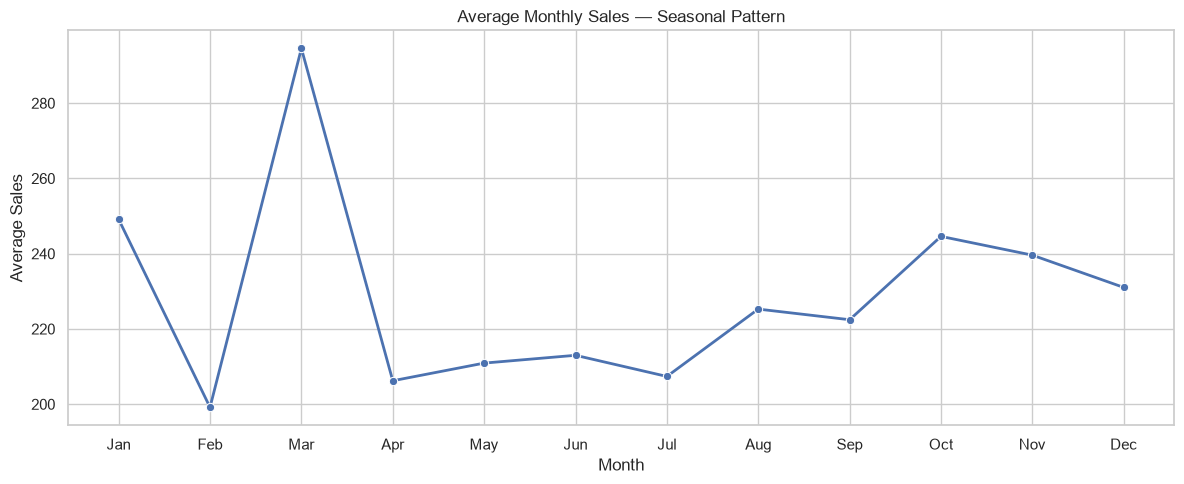

In [218]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    x=month_names,
    y=monthly_seasonality.values,
    marker="o",
    linewidth=2
)

plt.title("Average Monthly Sales — Seasonal Pattern")
plt.xlabel("Month")
plt.ylabel("Average Sales")

plt.tight_layout()
plt.show()

In [219]:
best_month = monthly_seasonality.idxmax()
worst_month = monthly_seasonality.idxmin()

best_month_sales = monthly_seasonality.max()
worst_month_sales = monthly_seasonality.min()

print(
    f"Highest average sales month: {month_names[best_month - 1]} "
    f"(${best_month_sales:,.2f})"
)

print(
    f"Lowest average sales month: {month_names[worst_month - 1]} "
    f"(${worst_month_sales:,.2f})"
)

Highest average sales month: Mar ($294.55)
Lowest average sales month: Feb ($199.17)


In [220]:
sales_heatmap = df.pivot_table(
    values="Sales",
    index="Year",
    columns="Month",
    aggfunc="sum"
)

sales_heatmap

Month,1,2,3,4,5,6,7,8,9,10,11,12
Year,,,,,,,,,,,,
2014,14236.8950,4519.8920,55691.0090,28295.3450,23648.2870,34595.1276,33946.393,27909.4685,81777.3508,31453.3930,78628.7167,69545.6205
2015,18174.0756,11951.4110,38726.2520,34195.2085,30131.6865,24797.2920,28765.325,36898.3322,64595.9180,31404.9235,75972.5635,74919.5212
2016,18542.4910,22978.8150,51715.8750,38750.0390,56987.7280,40344.5340,39261.963,31115.3743,73410.0249,59687.7450,79411.9658,96999.0430
2017,43971.3740,20301.1334,58872.3528,36521.5361,44261.1102,52981.7257,45264.416,63120.8880,87866.6520,77776.9232,118447.8250,83829.3188


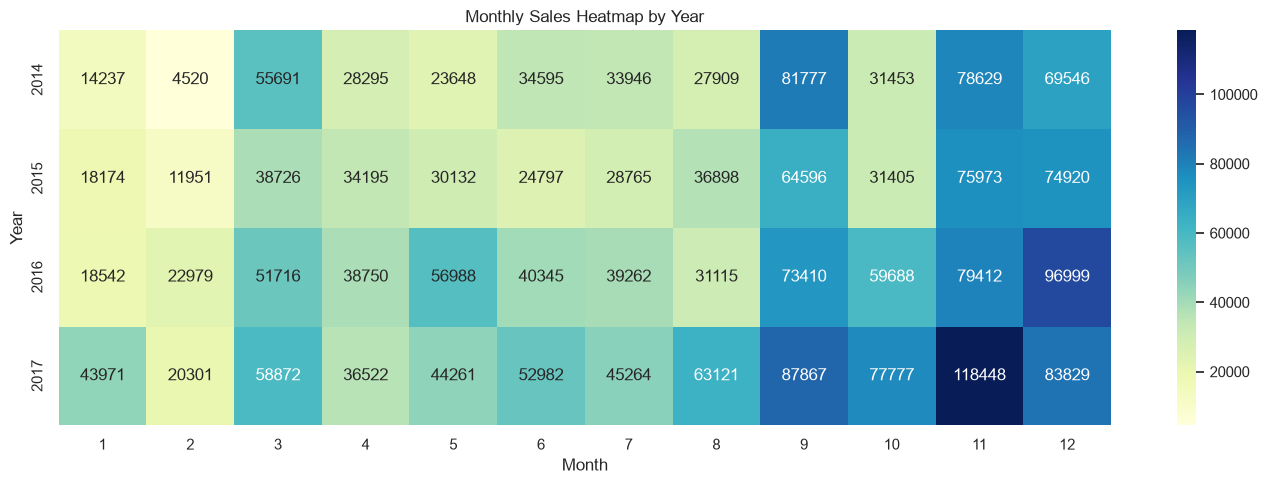

In [221]:
plt.figure(figsize=(14, 5))

sns.heatmap(
    sales_heatmap,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Monthly Sales Heatmap by Year")
plt.xlabel("Month")
plt.ylabel("Year")

plt.tight_layout()

plt.savefig(
    "../outputs/sales_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [222]:
top_months = (
    df.groupby("Year-Month")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
    .sort_values("Sales", ascending=False)
    .head(10)
)

top_months

,Sales,Profit
Year-Month,,
2017-11,118447.8250,9690.1037
2016-12,96999.0430,17885.3093
2017-09,87866.6520,10991.5556
2017-12,83829.3188,8483.3468
2014-09,81777.3508,8328.0994
2016-11,79411.9658,4011.4075
2014-11,78628.7167,9292.1269
2017-10,77776.9232,9275.2755
2015-11,75972.5635,12474.7884


In [223]:
bottom_months = (
    df.groupby("Year-Month")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
    .sort_values("Sales")
    .head(10)
)

bottom_months

,Sales,Profit
Year-Month,,
2014-02,4519.8920,862.3084
2015-02,11951.4110,2813.8508
2014-01,14236.8950,2450.1907
2015-01,18174.0756,-3281.0070
2016-01,18542.4910,2824.8233
2017-02,20301.1334,1613.8720
2016-02,22978.8150,5004.5795
2014-05,23648.2870,2738.7096
2015-06,24797.2920,3335.5572


In [224]:
seasonal_analysis = (
    df.groupby(["Year", "Month"])["Sales"]
    .sum()
    .reset_index()
)

average_monthly_sales = (
    seasonal_analysis
    .groupby("Month")["Sales"]
    .mean()
)

average_monthly_sales

Month
1     23731.208900
2     14937.812850
3     51251.372200
4     34440.532150
5     38757.202925
6     38179.669825
7     36809.524250
8     39761.015750
9     76912.486425
10    50080.746175
11    88115.267750
12    81323.375875
Name: Sales, dtype: float64

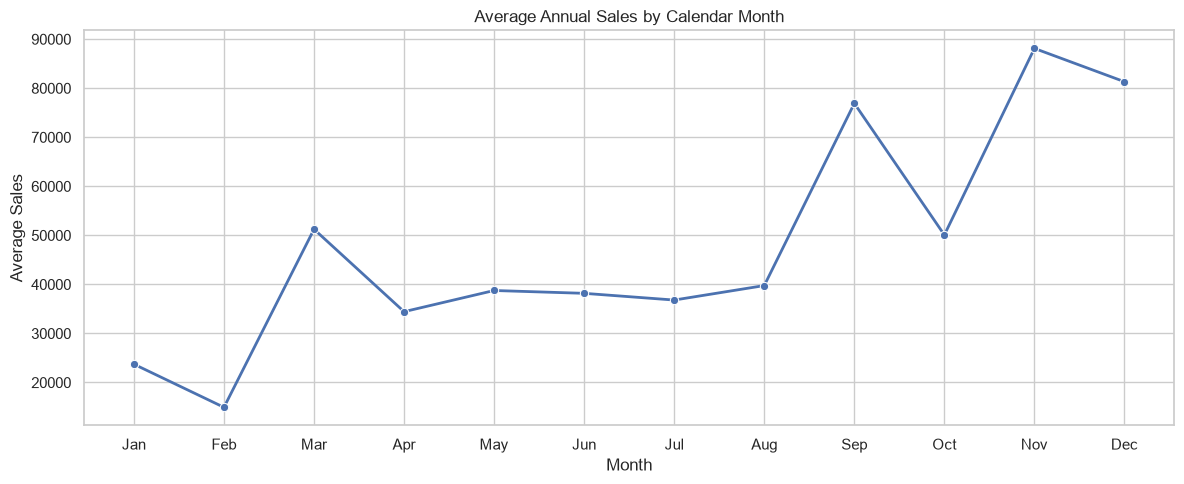

In [225]:
month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=month_names,
    y=average_monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Average Annual Sales by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Sales")

plt.tight_layout()

plt.savefig(
    "../outputs/seasonal_sales_pattern.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [226]:
product_performance = (
    df.groupby("Product Name")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"),
        Orders=("Order ID", "nunique")
    )
)

product_performance["Profit Margin (%)"] = (
    product_performance["Profit"]
    / product_performance["Sales"]
    * 100
)

product_performance = product_performance.sort_values(
    "Sales",
    ascending=False
)

product_performance.head(10)

,Sales,Profit,Quantity,Orders,Profit Margin (%)
Product Name,,,,,
Canon imageCLASS 2200 Advanced Copier,61599.824,2.519993e+04,20,5,4.090909e+01
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7.753039e+03,31,10,2.824074e+01
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1.811078e+03,6,1,-8.000000e+00
HON 5400 Series Task Chairs for Big and Tall,21870.576,5.684342e-14,39,8,2.599082e-16
GBC DocuBind TL300 Electric Binding System,19823.479,2.233505e+03,37,11,1.126697e+01
GBC Ibimaster 500 Manual ProClick Binding System,19024.500,7.609800e+02,48,9,4.000000e+00
Hewlett Packard LaserJet 3310 Copier,18839.686,6.983884e+03,38,8,3.707006e+01
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4.094977e+03,12,3,2.228571e+01
GBC DocuBind P400 Electric Binding System,17965.068,-1.878166e+03,27,6,-1.045455e+01


In [227]:
top_profit_products = product_performance.sort_values(
    "Profit",
    ascending=False
).head(10)

top_profit_products

,Sales,Profit,Quantity,Orders,Profit Margin (%)
Product Name,,,,,
Canon imageCLASS 2200 Advanced Copier,61599.824,25199.9280,20,5,40.909091
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7753.0390,31,10,28.240741
Hewlett Packard LaserJet 3310 Copier,18839.686,6983.8836,38,8,37.070064
Canon PC1060 Personal Laser Copier,11619.834,4570.9347,19,4,39.337349
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4094.9766,12,3,22.285714
Ativa V4110MDD Micro-Cut Shredder,7699.890,3772.9461,11,2,49.000000
"3D Systems Cube Printer, 2nd Generation, Magenta",14299.890,3717.9714,11,2,26.000000
Plantronics Savi W720 Multi-Device Wireless Headset System,9367.290,3696.2820,24,7,39.459459
Ibico EPK-21 Electric Binding System,15875.916,3345.2823,13,3,21.071429


In [228]:
bottom_profit_products = product_performance.sort_values(
    "Profit"
).head(10)

bottom_profit_products

,Sales,Profit,Quantity,Orders,Profit Margin (%)
Product Name,,,,,
Cubify CubeX 3D Printer Double Head Print,11099.963,-8879.9704,9,3,-80.000000
Lexmark MX611dhe Monochrome Laser Printer,16829.901,-4589.9730,18,4,-27.272727
Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904,4,1,-48.000000
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.640,-2876.1156,27,5,-29.000000
Bush Advantage Collection Racetrack Conference Table,9544.725,-1934.3976,33,7,-20.266667
GBC DocuBind P400 Electric Binding System,17965.068,-1878.1662,27,6,-10.454545
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1811.0784,6,1,-8.000000
Martin Yale Chadless Opener Electric Letter Opener,16656.200,-1299.1836,22,6,-7.800000
Balt Solid Wood Round Tables,6518.754,-1201.0581,19,4,-18.424658


In [229]:
subcategory_profitability = (
    df.groupby("Sub-Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
)

subcategory_profitability["Profit Margin (%)"] = (
    subcategory_profitability["Profit"]
    / subcategory_profitability["Sales"]
    * 100
)

subcategory_profitability.sort_values(
    "Profit"
)

,Sales,Profit,Quantity,Profit Margin (%)
Sub-Category,,,,
Tables,206965.5320,-17725.4811,1241,-8.564460
Bookcases,114879.9963,-3472.5560,868,-3.022768
Supplies,46673.5380,-1189.0995,647,-2.547695
Fasteners,3024.2800,949.5182,914,31.396504
Machines,189238.6310,3384.7569,440,1.788618
Labels,12486.3120,5546.2540,1400,44.418672
Art,27118.7920,6527.7870,3000,24.071083
Envelopes,16476.4020,6964.1767,906,42.267582
Furnishings,91705.1640,13059.1436,3563,14.240358


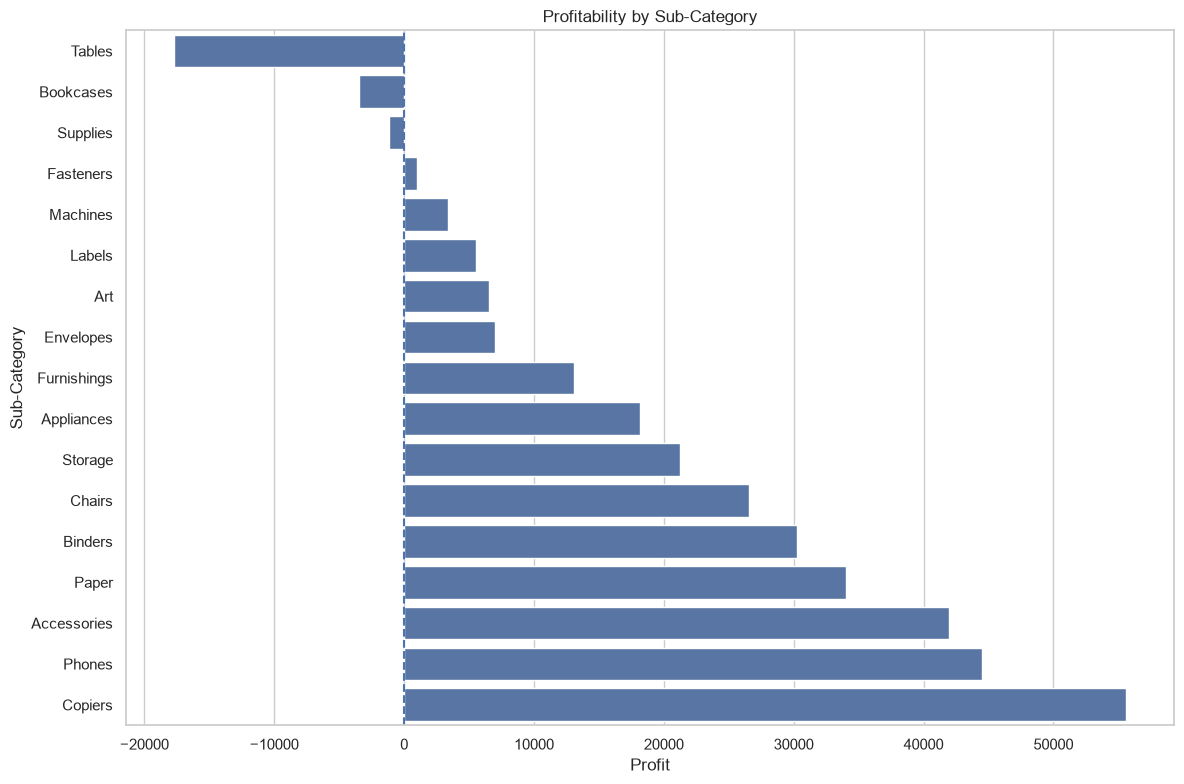

In [230]:
subcategory_plot_data = (
    subcategory_profitability
    .sort_values("Profit")
    .reset_index()
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=subcategory_plot_data,
    x="Profit",
    y="Sub-Category"
)

plt.axvline(
    0,
    linestyle="--"
)

plt.title("Profitability by Sub-Category")
plt.xlabel("Profit")
plt.ylabel("Sub-Category")

plt.tight_layout()

plt.savefig(
    "../outputs/subcategory_profitability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Discount and Profitability Analysis

Discount levels are analyzed to investigate their relationship with
profitability and identify whether higher discounting is associated
with reduced or negative profit.

In [231]:
discount_analysis = (
    df.groupby("Discount")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"),
        Orders=("Order ID", "nunique")
    )
)

discount_analysis["Profit Margin (%)"] = (
    discount_analysis["Profit"]
    / discount_analysis["Sales"]
    * 100
)

discount_analysis

,Sales,Profit,Quantity,Orders,Profit Margin (%)
Discount,,,,,
0.00,1.087908e+06,320987.6032,18267,2644,29.505019
0.10,5.436935e+04,9029.1770,373,89,16.607108
0.15,2.755852e+04,1418.9915,198,51,5.149012
0.20,7.645944e+05,90337.3060,13660,2407,11.815063
0.30,1.032267e+05,-10369.2774,849,211,-10.045155
0.32,1.449346e+04,-2391.1377,105,27,-16.498047
0.40,1.164178e+05,-23057.0504,786,185,-19.805437
0.45,5.484974e+03,-2493.1111,45,10,-45.453472
0.50,5.891854e+04,-20506.4281,241,64,-34.804712


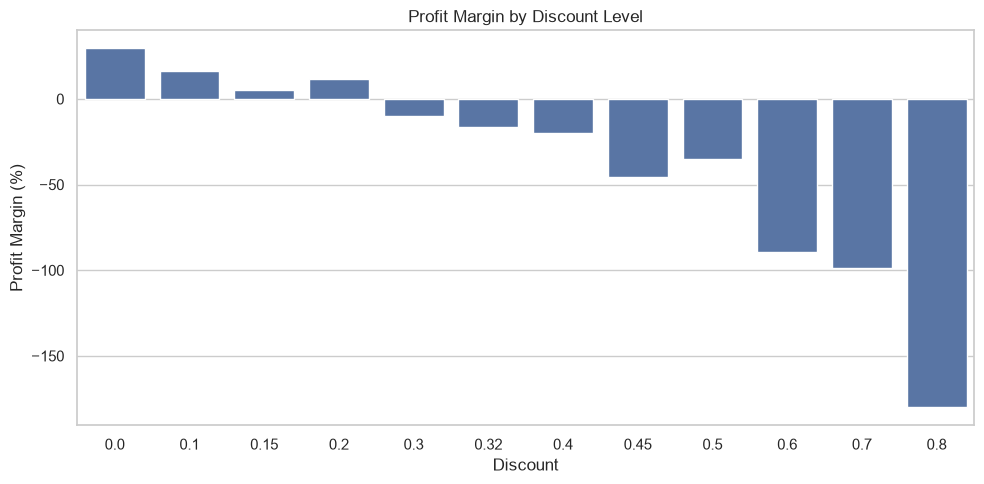

In [232]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=discount_analysis.reset_index(),
    x="Discount",
    y="Profit Margin (%)"
)

plt.title("Profit Margin by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Profit Margin (%)")

plt.tight_layout()
plt.show()

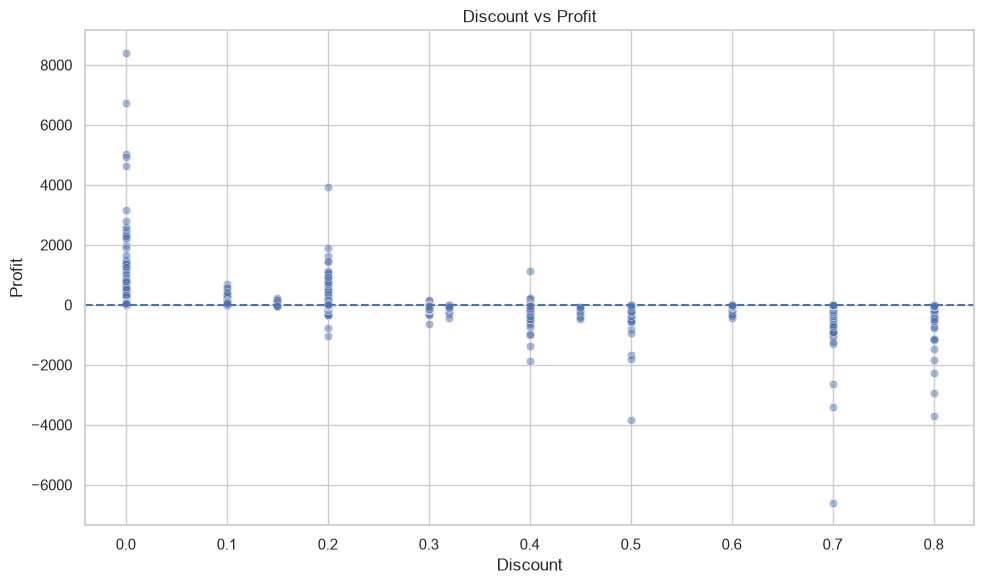

In [233]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    alpha=0.5
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.tight_layout()

plt.savefig(
    "../outputs/discount_vs_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [234]:
average_profit_by_discount = (
    df.groupby("Discount")["Profit"]
    .mean()
    .sort_index()
)

average_profit_by_discount

Discount
0.00     66.900292
0.10     96.055074
0.15     27.288298
0.20     24.702572
0.30    -45.679636
0.32    -88.560656
0.40   -111.927429
0.45   -226.646464
0.50   -310.703456
0.60    -43.077212
0.70    -95.874060
0.80   -101.796797
Name: Profit, dtype: float64

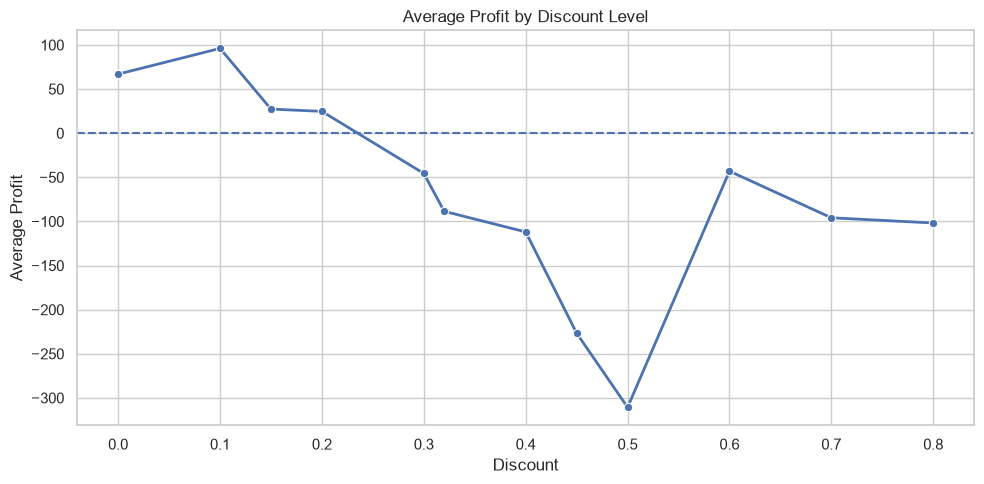

In [235]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    x=average_profit_by_discount.index,
    y=average_profit_by_discount.values,
    marker="o",
    linewidth=2
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("Average Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Average Profit")

plt.tight_layout()
plt.show()

In [236]:
tables_discount = (
    df[df["Sub-Category"] == "Tables"]
    .groupby("Discount")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum"),
        Orders=("Order ID", "nunique")
    )
)

tables_discount["Profit Margin (%)"] = (
    tables_discount["Profit"]
    / tables_discount["Sales"]
    * 100
)

tables_discount

,Sales,Profit,Quantity,Orders,Profit Margin (%)
Discount,,,,,
0.00,71578.760,13276.2997,310,70,18.547820
0.20,45430.232,-303.5580,281,69,-0.668185
0.30,25182.150,-3402.3276,180,51,-13.510870
0.40,45614.406,-16187.3968,292,72,-35.487466
0.45,5484.974,-2493.1111,45,10,-45.453472
0.50,13675.010,-8615.3873,133,35,-63.000958


In [237]:
df["Profit Status"] = np.where(
    df["Profit"] >= 0,
    "Profitable",
    "Loss"
)

In [238]:
profit_status = (
    df.groupby("Profit Status")
    .agg(
        Transactions=("Profit", "count"),
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Average_Discount=("Discount", "mean")
    )
)

profit_status

,Transactions,Sales,Profit,Average_Discount
Profit Status,,,,
Loss,1871,4.687072e+05,-156131.2857,0.480887
Profitable,8123,1.828494e+06,442528.3074,0.081417


## 8. Key Business Insights

### 1. Strong long-term sales growth

Sales increased from approximately $484K in 2014 to $733K in 2017,
representing approximately 51% growth over the analysis period.

After a small decline in 2015, sales increased by 29.47% in 2016
and another 20.36% in 2017.

### 2. Strong seasonal pattern

November and December are the strongest calendar months based on
average annual monthly sales, while February is the weakest.

This suggests that demand is concentrated toward the end of the year.

### 3. Technology is the strongest category by profit

Technology generated approximately $836K in sales and $145K in profit,
making it the strongest category in terms of profitability.

### 4. Tables generate significant revenue but destroy profit

The Tables subcategory generated approximately $207K in sales but
recorded a loss of approximately $17.7K, resulting in a negative
profit margin of approximately 8.56%.

### 5. Higher discounts are associated with lower profitability

Aggregate profitability becomes negative at discount levels of 30%
and above. At an 80% discount level, the aggregate profit margin
falls to approximately -180%.

### 6. Loss-making transactions receive substantially higher discounts

Loss-making transactions have an average discount of approximately
48.1%, compared with approximately 8.1% for profitable transactions.

### 7. Regional performance varies significantly

The West region has the highest sales and profit margin, while the
Central region has a substantially lower profit margin.

The West generated approximately $725K in sales with a 14.94% margin,
while Central generated approximately $501K with a 7.92% margin.

## 9. Business Recommendations

### 1. Review high-discount pricing strategies

Discount levels of 30% or higher should be reviewed carefully because
these transactions show negative aggregate profitability.

### 2. Reassess the Tables subcategory

Tables should be investigated for pricing, procurement costs, discount
levels, and product-level profitability. Loss-making products should
be identified for corrective action.

### 3. Prioritize profitable product categories

Technology and high-margin subcategories such as Copiers, Accessories,
Paper, and Labels should receive strategic attention because they
generate strong profitability relative to their sales.

### 4. Prepare for year-end demand

The strong November and December sales pattern suggests that inventory,
marketing, and operational planning should be strengthened before the
year-end demand period.

### 5. Investigate regional profitability

The large difference between West and Central profit margins suggests
that regional pricing, product mix, discounting, or operating factors
should be investigated further.

### 6. Use profitability alongside sales for decision-making

Products and categories should not be evaluated using sales alone.
Profit and profit margin should be included in product and pricing
decisions.